# Обработка фотографии документа
### Домашнее задание 1 по компьютерному зрению · OpenCV

**Изображение:** `IMG_8304.jpeg` · **Автор:** Ноздрин Виктор Владимирович, 3826М1ФИии1


## 1. Подготовка и исходное изображение

Используются только классические операции OpenCV и NumPy. Matplotlib служит
для визуализации. Модели распознавания, OCR-библиотеки, готовая электронная версия
текста статьи и её PDF не используются. Короткие фрагменты вручную переписаны
с фотографии только для контроля.


In [1]:
from pathlib import Path
from html import escape
import hashlib
import platform
import cv2
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display, HTML, Markdown

%matplotlib inline

IMAGE_PATH = Path("IMG_8304.jpeg")
PARALLEL_TOLERANCE_DEG = 0.20
HORIZONTAL_TOLERANCE_DEG = 0.15
BLUE, TEAL, ORANGE = "#285b92", "#126e73", "#cc7a24"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "semibold", "axes.titlesize": 13,
    "figure.dpi": 120, "savefig.dpi": 150,
})
cv2.setNumThreads(2)
np.random.seed(0)

def show_image(ax, image, title):
    if image.ndim == 3:
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    else:
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title, loc="left", pad=12)
    ax.axis("off")

def table(headers, rows, collapsed=None):
    head = "".join(f"<th style='text-align:left;padding:8px 12px;border-bottom:2px solid #126e73'>{escape(str(x))}</th>" for x in headers)
    body = "".join("<tr>" + "".join(f"<td style='padding:7px 12px;border-bottom:1px solid #dfe7e7'>{escape(str(x))}</td>" for x in row) + "</tr>" for row in rows)
    content = f"<table style='font-family:system-ui;font-size:14px;border-collapse:collapse'><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"
    if collapsed:
        content = f"<details><summary style='cursor:pointer;color:#126e73;padding:12px 0;font-weight:600'>{escape(collapsed)}</summary>{content}</details>"
    display(HTML(content))

In [2]:
def read_image(path):
    image = cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f'Не удалось прочитать изображение: {path}')
    return image

Параметр,Значение
Файл,IMG_8304.jpeg
"Разрешение, ширина × высота",3024 × 4032 px
Python / OpenCV / NumPy,3.13.16 / 5.0.0 / 2.1.3
Matplotlib,3.10.0
SHA-256 входного файла,eeac658c29c2dbb8199206d1ce9764a14b1ed18a4b4bee74932df553111d5710


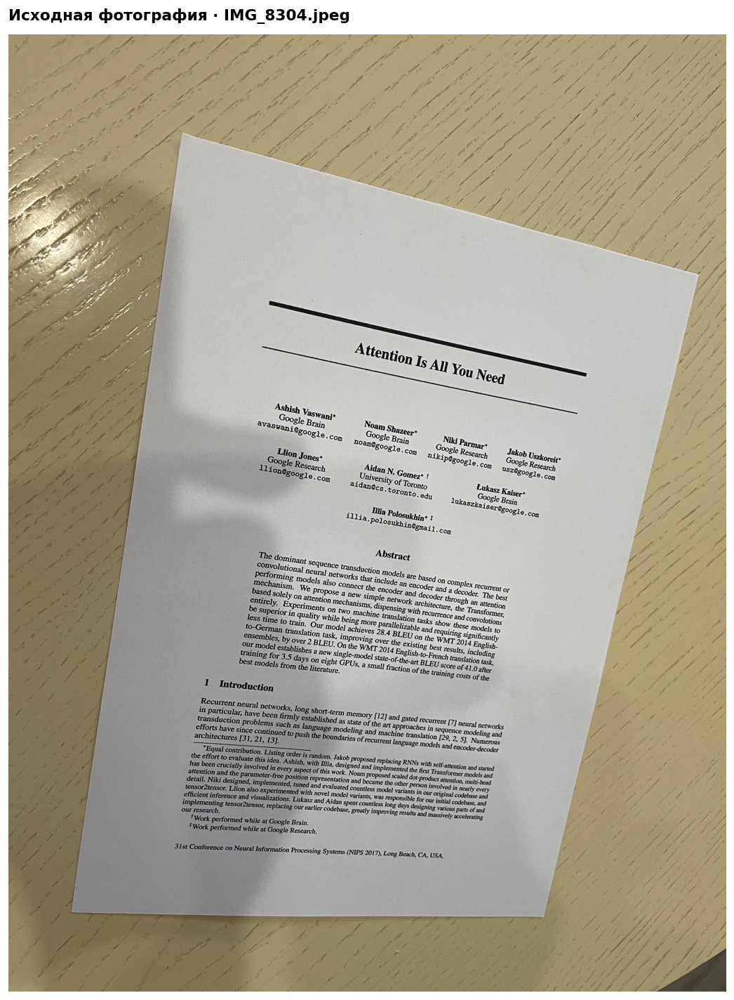

In [3]:
original = read_image(IMAGE_PATH)
source_hash = hashlib.sha256(IMAGE_PATH.read_bytes()).hexdigest()
table(["Параметр", "Значение"], [
    ["Файл", IMAGE_PATH.name],
    ["Разрешение, ширина × высота", f"{original.shape[1]} × {original.shape[0]} px"],
    ["Python / OpenCV / NumPy", f"{platform.python_version()} / {cv2.__version__} / {np.__version__}"],
    ["Matplotlib", matplotlib.__version__],
    ["SHA-256 входного файла", source_hash],
])
fig, ax = plt.subplots(figsize=(9, 12))
show_image(ax, original, "Исходная фотография · IMG_8304.jpeg")
plt.tight_layout()
plt.show()

## 2. Границы и четыре угла документа

На фотографии бумага почти нейтральная по цвету, а стол имеет жёлтый оттенок.
Поэтому используем **насыщенность S в HSV**, а порог определяем методом Оцу.
Замыкание заполняет небольшие разрывы маски. Среди крупных внешних контуров
выбираем выпуклый четырёхугольник (`findContours`, `approxPolyDP`).

Для уточнения углов аппроксимируем каждую сторону прямой (`fitLine`) по точкам
контура вдали от вершин. Пересечения соседних прямых дают четыре угла.
Координаты возвращаются в разрешение исходной фотографии; вручную углы не задаются.

In [4]:
def order_corners(points):
    points = np.asarray(points, dtype=np.float32).reshape(4, 2)
    total = points.sum(axis=1)
    difference = np.diff(points, axis=1).ravel()
    ordered = points[[np.argmin(total), np.argmin(difference),
                      np.argmax(total), np.argmax(difference)]]
    if len(np.unique(ordered, axis=0)) != 4:
        raise ValueError('Не удалось однозначно упорядочить углы.')
    return ordered


def line_intersection(first, second):
    p, v = first
    q, u = second
    t = np.linalg.solve(np.column_stack((v, -u)), q - p)[0]
    return p + t * v


def find_document(image, detection_height=1400):
    scale = min(1.0, detection_height / image.shape[0])
    small = cv2.resize(image, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    hsv = cv2.cvtColor(small, cv2.COLOR_BGR2HSV)
    saturation = cv2.GaussianBlur(hsv[:, :, 1], (7, 7), 0)
    threshold, mask = cv2.threshold(saturation, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    mask[hsv[:, :, 2] < 65] = 0
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (17, 17))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    candidates = []
    for contour in contours:
        area = cv2.contourArea(contour)
        if area < .2 * mask.size:
            continue
        polygon = cv2.approxPolyDP(contour, .015 * cv2.arcLength(contour, True), True)
        if len(polygon) == 4 and cv2.isContourConvex(polygon):
            candidates.append((area, polygon, contour))
    if not candidates:
        raise RuntimeError('Четырёхугольник документа не найден. Проверьте маску насыщенности.')
    _, polygon, contour = max(candidates, key=lambda item: item[0])
    approximate = order_corners(polygon)
    edge_points = contour.reshape(-1, 2).astype(np.float32)
    fitted = []
    for index in range(4):
        start, end = approximate[index], approximate[(index + 1) % 4]
        direction = end - start
        length = np.linalg.norm(direction)
        unit = direction / length
        relative = edge_points - start
        along = relative @ unit
        normal = np.abs(relative[:, 0] * unit[1] - relative[:, 1] * unit[0])
        selected = edge_points[(along > .08 * length) & (along < .92 * length) & (normal < 8)]
        if len(selected) < 20:
            raise RuntimeError('Недостаточно точек для уточнения стороны листа.')
        vx, vy, x, y = cv2.fitLine(selected, cv2.DIST_HUBER, 0, .01, .01).ravel()
        fitted.append((np.array([x, y]), np.array([vx, vy])))
    refined = np.array([line_intersection(fitted[(index - 1) % 4], fitted[index])
                        for index in range(4)], np.float32) / scale
    return refined, {'small': small, 'mask': mask, 'threshold': float(threshold),
                     'approximate': approximate / scale}

Угол,"x, px","y, px"
TL,735.89,421.08
TR,2904.02,1013.40
BR,2250.09,3716.77
BL,264.96,3702.87


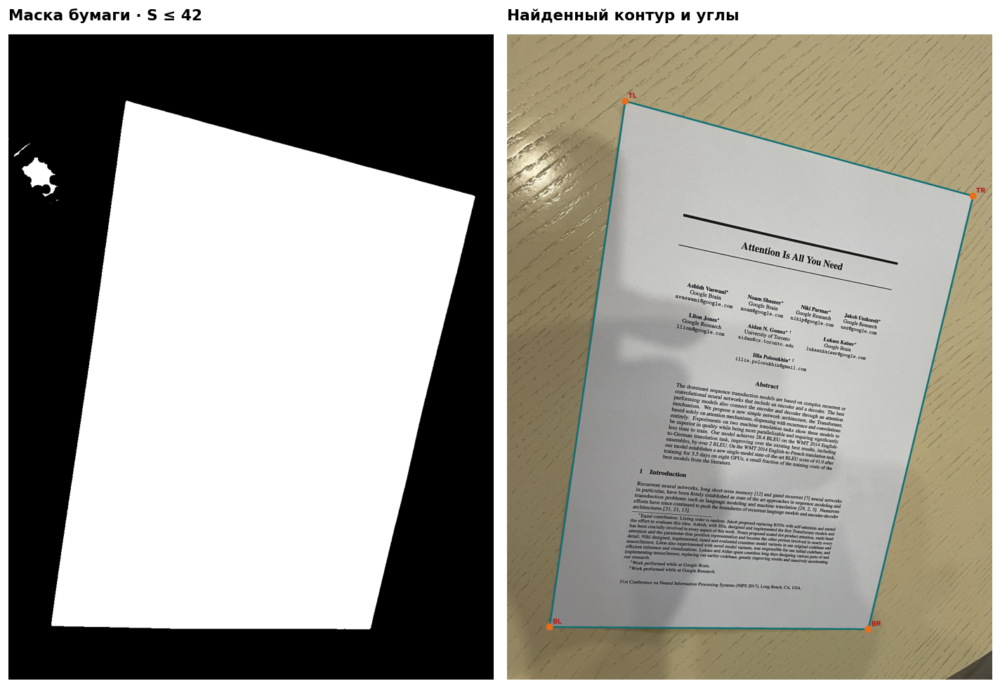

In [5]:
corners, boundary_data = find_document(original)
corner_names = ["TL", "TR", "BR", "BL"]
table(["Угол", "x, px", "y, px"],
      [[name, f"{x:.2f}", f"{y:.2f}"] for name, (x, y) in zip(corner_names, corners)])
corner_overlay = original.copy()
cv2.polylines(corner_overlay, [np.round(corners).astype(np.int32)], True, (115, 110, 15), 9)
for name, point in zip(corner_names, corners):
    x, y = np.round(point).astype(int)
    cv2.circle(corner_overlay, (x, y), 22, (30, 110, 230), -1)
    cv2.putText(corner_overlay, name, (x + 20, max(45, y - 20)),
                cv2.FONT_HERSHEY_SIMPLEX, 1.5, (20, 20, 180), 4, cv2.LINE_AA)
fig, axes = plt.subplots(1, 2, figsize=(12, 9))
show_image(axes[0], boundary_data["mask"], f"Маска бумаги · S ≤ {boundary_data['threshold']:.0f}")
show_image(axes[1], corner_overlay, "Найденный контур и углы")
plt.tight_layout()
plt.show()

## 3. Преобразование перспективы

Упорядоченные углы сопоставляем вершинам прямоугольника. Матрица гомографии
$H$ вычисляется через `getPerspectiveTransform`, а изображение — через
`warpPerspective`:

$$\lambda\begin{bmatrix}u\\v\\1\end{bmatrix}
=H\begin{bmatrix}x\\y\\1\end{bmatrix}.$$

Размер выходного прямоугольника оценивается по максимальным длинам
противоположных сторон листа. Физический размер бумаги не предполагается
известным; это геометрическое выравнивание, а не метрическая калибровка камеры.

In [6]:
def rectify_document(image, corners):
    tl, tr, br, bl = corners
    width = int(round(max(np.linalg.norm(tr - tl), np.linalg.norm(br - bl))))
    height = int(round(max(np.linalg.norm(bl - tl), np.linalg.norm(br - tr))))
    destination = np.float32([[0, 0], [width - 1, 0], [width - 1, height - 1], [0, height - 1]])
    matrix = cv2.getPerspectiveTransform(corners.astype(np.float32), destination)
    result = cv2.warpPerspective(image, matrix, (width, height), flags=cv2.INTER_CUBIC,
                                 borderMode=cv2.BORDER_REPLICATE)
    return result, matrix

Параметр,Значение
Начальный размер результата,2248 × 3315 px
Определитель H,0.581171


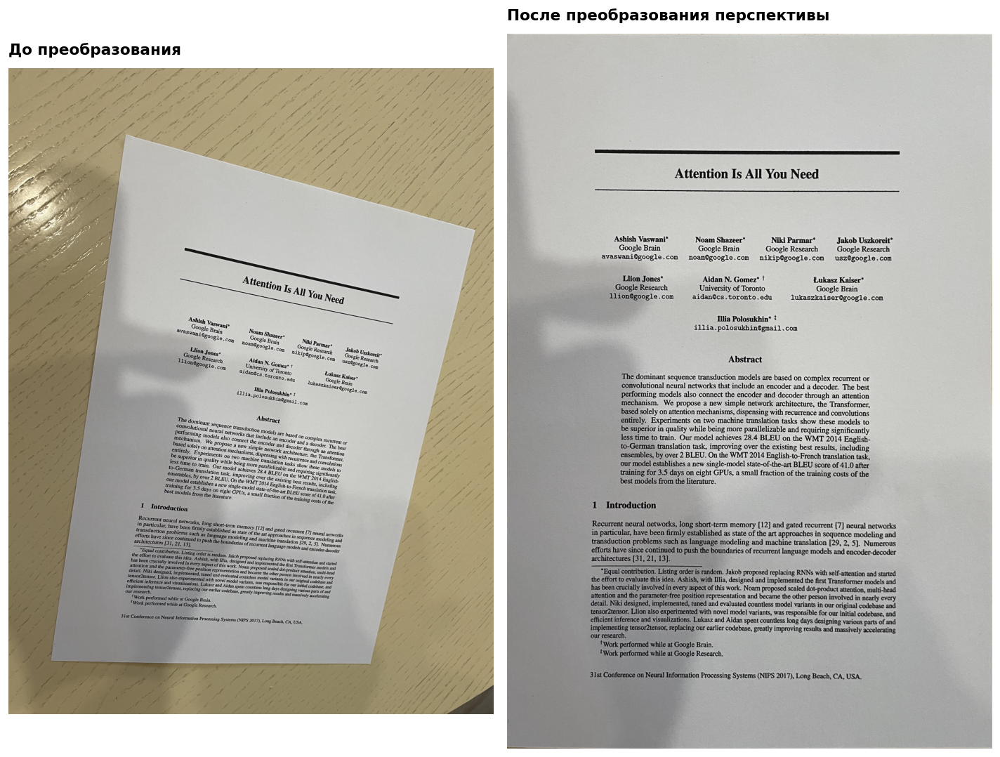

In [7]:
rectified_initial, homography_initial = rectify_document(original, corners)
table(["Параметр", "Значение"], [
    ["Начальный размер результата", f"{rectified_initial.shape[1]} × {rectified_initial.shape[0]} px"],
    ["Определитель H", f"{np.linalg.det(homography_initial):.6f}"],
])
fig, axes = plt.subplots(1, 2, figsize=(12, 9))
show_image(axes[0], original, "До преобразования")
show_image(axes[1], rectified_initial, "После преобразования перспективы")
plt.tight_layout()
plt.show()

## 4. Контроль параллельности и уточнение выравнивания

Независимая проверка использует **две разные печатные линейки вокруг заголовка**,
а не границы листа, которыми уже задана гомография. После бинаризации находим
длинные тонкие связные компоненты в верхней части страницы. По пикселям каждой
компоненты отдельно строим прямую `fitLine`; толстая линейка считается одной
линией, а не двумя её краями.

Направление отрезка: $\theta=\operatorname{atan2}(\Delta y,\Delta x)$.
Разность направлений вычисляется по модулю $180^\circ$.
Приняты допуски: **0,20° для параллельности**, **0,15° для горизонтальности**.

Для сравнения с исходной фотографией те же отрезки переносим обратной
гомографией. Если после исправления перспективы остаётся общий наклон,
устраняем его средним углом двух линий. Итоговую матрицу составляем как
$H_{final}=R H$ и преобразуем **исходную фотографию один раз**.
Холст расширяется, чтобы не обрезать лист при повороте.

In [8]:
def detect_header_rules(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if image.ndim == 3 else image
    height, width = gray.shape
    binary = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                   cv2.THRESH_BINARY_INV, 51, 15)
    # Two long printed rules in the upper half; text and page borders are excluded.
    binary[int(.44 * height):] = 0
    binary[:int(.08 * height)] = 0
    binary[:, :int(.08 * width)] = 0
    binary[:, int(.92 * width):] = 0
    count, labels, stats, _ = cv2.connectedComponentsWithStats(binary, 8)
    candidates = [index for index in range(1, count)
                  if stats[index, 2] > .4 * width
                  and stats[index, 3] < .06 * height
                  and stats[index, 2] / stats[index, 3] > 15]
    candidates = sorted(candidates, key=lambda index: stats[index, 2], reverse=True)[:2]
    if len(candidates) != 2:
        raise RuntimeError('Нужны две независимые печатные линии.')
    lines = []
    for index in sorted(candidates, key=lambda index: stats[index, 1]):
        yy, xx = np.nonzero(labels == index)
        points = np.column_stack((xx, yy)).astype(np.float32)
        vx, vy, x, y = cv2.fitLine(points, cv2.DIST_HUBER, 0, .001, .001).ravel()
        slope = float(vy / vx)
        intercept = float(y - slope * x)
        ends = np.float32([[xx.min(), slope * xx.min() + intercept],
                           [xx.max(), slope * xx.max() + intercept]])
        lines.append({'slope': slope, 'intercept': intercept, 'points': ends,
                      'angle': float(np.degrees(np.arctan(slope)))})
    return lines


def angle_of_segment(points):
    delta = points[1] - points[0]
    return float((np.degrees(np.arctan2(delta[1], delta[0])) + 90) % 180 - 90)


def angle_difference(first, second):
    return float(abs((first - second + 90) % 180 - 90))


def refine_common_tilt(original, rectified, transform, lines, tolerance=.15):
    tilt = float(np.mean([line['angle'] for line in lines]))
    if abs(tilt) <= tolerance:
        return rectified.copy(), transform.copy(), 0.0
    height, width = rectified.shape[:2]
    rotation = cv2.getRotationMatrix2D((width / 2, height / 2), tilt, 1)
    cosine, sine = abs(rotation[0, 0]), abs(rotation[0, 1])
    new_width = int(np.ceil(cosine * width + sine * height))
    new_height = int(np.ceil(sine * width + cosine * height))
    rotation[0, 2] += (new_width - width) / 2
    rotation[1, 2] += (new_height - height) / 2
    composed = np.vstack((rotation, [0, 0, 1])) @ transform
    final = cv2.warpPerspective(original, composed, (new_width, new_height),
                                flags=cv2.INTER_CUBIC, borderValue=(255, 255, 255))
    return final, composed, tilt

Этап,"Линия 1, °","Линия 2, °","Разница, °"
Исходное фото,12.7977,11.9131,0.8846
После гомографии,0.2912,0.2862,0.0050
После уточнения,0.0008,0.0011,0.0004


**Уточнение:** поворот на 0.2887°. **Проверка по двум линиям:** пройдена. Эта проверка подтверждает качество выравнивания в области заголовка; она не доказывает отсутствие всех локальных деформаций бумаги.

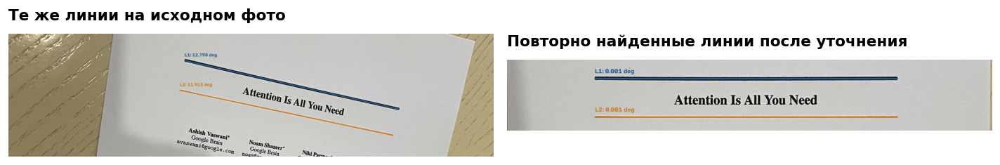

In [9]:
initial_rules = detect_header_rules(rectified_initial)
inverse_initial = np.linalg.inv(homography_initial)
source_rule_points = [cv2.perspectiveTransform(rule["points"][None], inverse_initial)[0]
                      for rule in initial_rules]
angles_source = [angle_of_segment(points) for points in source_rule_points]
angles_initial = [rule["angle"] for rule in initial_rules]
rectified, homography, correction_angle = refine_common_tilt(
    original, rectified_initial, homography_initial, initial_rules,
    tolerance=HORIZONTAL_TOLERANCE_DEG)
final_rules = detect_header_rules(rectified)
angles_final = [rule["angle"] for rule in final_rules]
parallel_error = angle_difference(*angles_final)
horizontal_error = max(abs(angle) for angle in angles_final)
geometry_ok = (parallel_error <= PARALLEL_TOLERANCE_DEG
               and horizontal_error <= HORIZONTAL_TOLERANCE_DEG)
table(["Этап", "Линия 1, °", "Линия 2, °", "Разница, °"], [
    ["Исходное фото", f"{angles_source[0]:.4f}", f"{angles_source[1]:.4f}", f"{angle_difference(*angles_source):.4f}"],
    ["После гомографии", f"{angles_initial[0]:.4f}", f"{angles_initial[1]:.4f}", f"{angle_difference(*angles_initial):.4f}"],
    ["После уточнения", f"{angles_final[0]:.4f}", f"{angles_final[1]:.4f}", f"{parallel_error:.4f}"],
])
display(Markdown(f"**Уточнение:** поворот на {correction_angle:.4f}°. "
                 f"**Проверка по двум линиям:** {'пройдена' if geometry_ok else 'не пройдена'}. "
                 "Эта проверка подтверждает качество выравнивания в области заголовка; "
                 "она не доказывает отсутствие всех локальных деформаций бумаги."))

def draw_rules(image, rules, labels):
    output = image.copy()
    for index, (points, label) in enumerate(zip(rules, labels)):
        first, second = np.round(points).astype(int)
        color = (146, 91, 40) if index == 0 else (36, 122, 204)
        cv2.line(output, tuple(first), tuple(second), color, 6, cv2.LINE_AA)
        cv2.putText(output, label, (int(first[0]), max(30, int(first[1]) - 25)),
                    cv2.FONT_HERSHEY_SIMPLEX, .95, color, 2, cv2.LINE_AA)
    return output

before_rules = draw_rules(original, source_rule_points,
                          [f"L{i+1}: {angle:.3f} deg" for i, angle in enumerate(angles_source)])
after_rules = draw_rules(rectified, [rule["points"] for rule in final_rules],
                         [f"L{i+1}: {angle:.3f} deg" for i, angle in enumerate(angles_final)])
fig, axes = plt.subplots(1, 2, figsize=(12, 7))
show_image(axes[0], before_rules[int(original.shape[0]*.24):int(original.shape[0]*.43)], "Те же линии на исходном фото")
show_image(axes[1], after_rules[int(rectified.shape[0]*.14):int(rectified.shape[0]*.24)], "Повторно найденные линии после уточнения")
plt.tight_layout()
plt.show()

## 5. Бинаризация текста и удаление линеек

Тень компенсируем делением на сглаженную оценку фона:
$I_{norm}=255\,I/(G_\sigma * I)$.
Далее автоматически выбираем порог методом Оцу: белые пиксели маски соответствуют печати.
Длинные горизонтальные элементы выделяем морфологическим открытием и удаляем;
границу листа и мелкий шум исключаем, стараясь сохранить буквы, цифры и пунктуацию.

In [11]:
def _runs(mask):
    edges = np.diff(np.r_[False, mask, False].astype(np.int8))
    return list(zip(np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)))


def prepare_text(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if image.ndim == 3 else image.copy()
    size = max(31, int(round(min(gray.shape) * 0.035)) | 1)
    background = cv2.GaussianBlur(gray, (size, size), 0)
    normalized = cv2.divide(gray, background, scale=255)
    _, binary = cv2.threshold(normalized, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    border = max(3, int(min(gray.shape) * 0.012))
    binary[:border] = binary[-border:] = 0
    binary[:, :border] = binary[:, -border:] = 0
    rules = cv2.morphologyEx(binary, cv2.MORPH_OPEN,
                             cv2.getStructuringElement(cv2.MORPH_RECT,
                                                       (max(80, int(gray.shape[1] * .08)), 1)))
    rules = cv2.dilate(rules, np.ones((3, 3), np.uint8))
    binary[rules > 0] = 0
    n, labels, stats, _ = cv2.connectedComponentsWithStats(binary, 8)
    keep = ((stats[:, 4] >= 3) & (stats[:, 3] < gray.shape[0] * .06)
            & (stats[:, 2] < gray.shape[1] * .08))
    keep[0] = False
    clean = (keep[labels].astype(np.uint8) * 255)
    return {"gray": gray, "normalized": normalized, "binary": clean, "rules": rules}

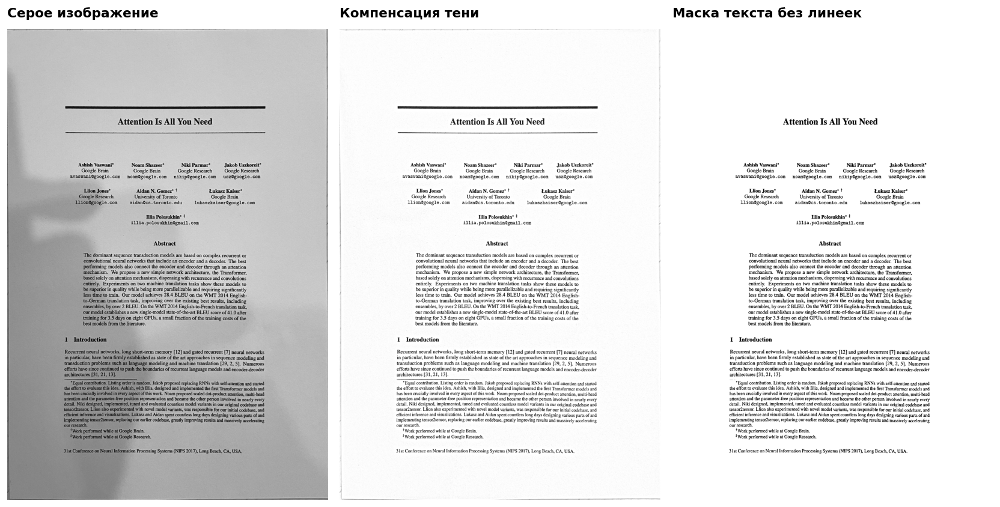

In [12]:
prepared = prepare_text(rectified)
fig, axes = plt.subplots(1, 3, figsize=(14, 9))
show_image(axes[0], prepared["gray"], "Серое изображение")
show_image(axes[1], prepared["normalized"], "Компенсация тени")
show_image(axes[2], 255 - prepared["binary"], "Маска текста без линеек")
plt.tight_layout()
plt.show()

## 6. Собственный алгоритм выделения и подсчёта строк

1. По связным компонентам оцениваем типичную высоту печатных знаков.
2. Горизонтальное расширение объединяет буквы и слова в строки, сохраняя
   большие промежутки между колонками авторов.
3. Фрагменты с сильным перекрытием по вертикали и небольшим промежутком
   объединяем; это позволяет присоединить номер раздела и знаки сносок.
4. Если несколько соседних строк оказались соединены, разделяем их по минимумам
   горизонтальной проекции. Для каждого прямоугольника возвращаем границы печати.

Число строк - число выделенных прямоугольников, а не число горизонтальных
уровней на странице. На контрольной визуализации каждая строка пронумерована.
Горизонтальная проекция показана как дополнительная диагностика расположения текста.

In [14]:
def detect_lines(binary):
    n, _, stats, _ = cv2.connectedComponentsWithStats(binary, 8)
    meaningful = stats[1:][(stats[1:, 4] >= 10) & (stats[1:, 3] >= 6)]
    if len(meaningful) == 0:
        return [], 10.0
    glyph_h = float(np.median(meaningful[:, 3]))
    kernel_w = max(5, int(round(glyph_h * 1.25)))
    joined = cv2.dilate(binary, cv2.getStructuringElement(cv2.MORPH_RECT, (kernel_w, 1)))
    n, _, stats, _ = cv2.connectedComponentsWithStats(joined, 8)
    boxes = []
    for x, y, w, h, area in stats[1:]:
        if area < 8 or h < glyph_h * .15:
            continue
        x0, y0 = max(0, x - 1), max(0, y - 1)
        x1, y1 = min(binary.shape[1], x + w + 1), min(binary.shape[0], y + h + 1)
        yy, xx = np.nonzero(binary[y0:y1, x0:x1])
        if len(xx):
            boxes.append([int(xx.min()+x0), int(yy.min()+y0),
                          int(xx.max()+x0+1), int(yy.max()+y0+1)])
    boxes.sort(key=lambda b: (b[1], b[0]))
    parent = list(range(len(boxes)))
    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i
    for i,a in enumerate(boxes):
        for j in range(i+1,len(boxes)):
            b=boxes[j]
            if b[1] >= a[3]:
                break
            overlap = min(a[3], b[3]) - max(a[1], b[1])
            gap = max(a[0], b[0]) - min(a[2], b[2])
            if overlap > .55*min(a[3]-a[1],b[3]-b[1]) and gap < glyph_h*2.8:
                parent[find(j)] = find(i)
    grouped = {}
    for i,a in enumerate(boxes):
        key=find(i)
        if key not in grouped:
            grouped[key]=a.copy()
        else:
            b=grouped[key]
            grouped[key]=[min(a[0],b[0]),min(a[1],b[1]),max(a[2],b[2]),max(a[3],b[3])]
    boxes=list(grouped.values())
    split_boxes=[]
    for x0,y0,x1,y1 in boxes:
        crop=binary[y0:y1,x0:x1]
        _,_,local_stats,_=cv2.connectedComponentsWithStats(crop,8)
        heights=[h for x,y,w,h,a in local_stats[1:] if a>=10 and h>=glyph_h*.4]
        local_h=float(np.median(heights)) if heights else glyph_h
        if y1-y0 > local_h*1.65:
            profile=np.count_nonzero(crop,axis=1)
            active=profile>max(2,profile.max()*.1)
            for a,b in _runs(~active):
                if a>0 and b<len(active) and b-a<=max(1,round(local_h*.08)):
                    active[a:b]=True
            bands=_runs(active)
            substantial=[(a,b) for a,b in bands if b-a>=local_h*.45]
            if len(substantial)>1:
                boundaries=[0]+[round((a[1]+b[0])/2) for a,b in zip(substantial[:-1],substantial[1:])]+[len(profile)]
                for a,b in zip(boundaries[:-1],boundaries[1:]):
                    yy,xx=np.nonzero(crop[a:b])
                    if len(xx):
                        split_boxes.append([x0+int(xx.min()),y0+a+int(yy.min()),
                                            x0+int(xx.max())+1,y0+a+int(yy.max())+1])
                continue
        split_boxes.append([x0,y0,x1,y1])
    boxes = [b for b in split_boxes if b[2]-b[0] >= glyph_h*1.3 and b[3]-b[1] >= glyph_h*.4]
    boxes.sort(key=lambda b: (b[1], b[0]))
    return boxes, glyph_h

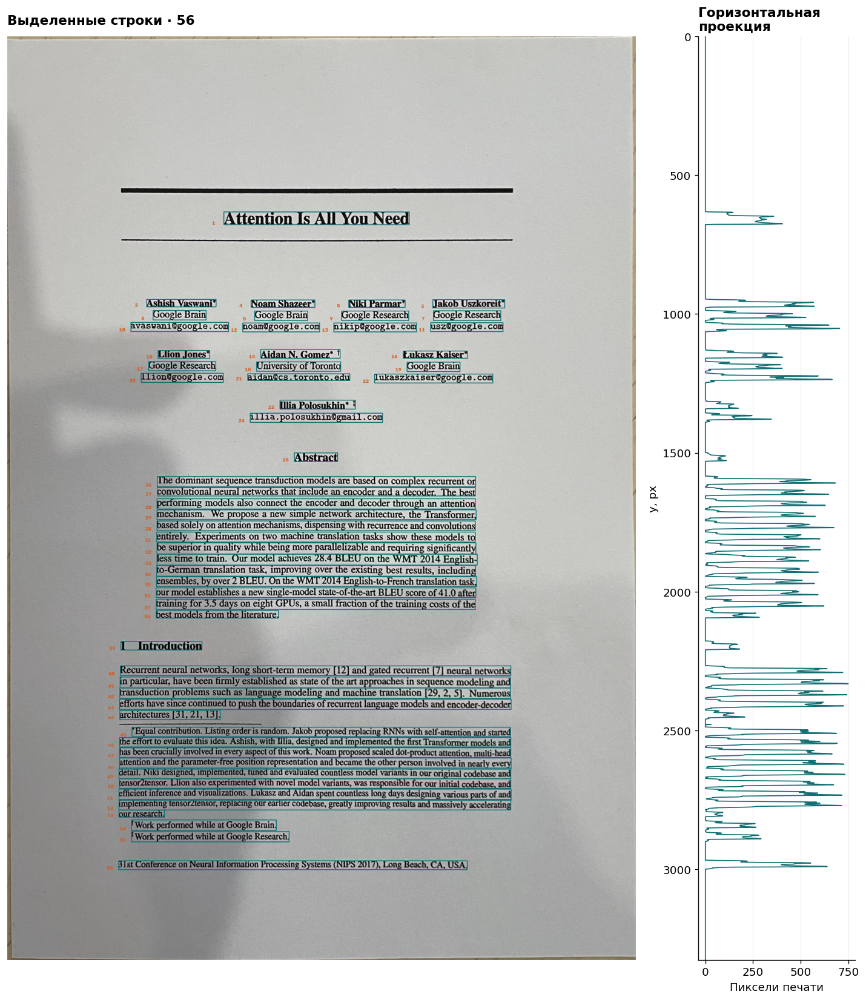

In [15]:
line_boxes, typical_height = detect_lines(prepared["binary"])
line_preview = rectified.copy()
for index, (x0, y0, x1, y1) in enumerate(line_boxes, 1):
    cv2.rectangle(line_preview, (x0, y0), (x1, y1), (115, 110, 15), 2)
    cv2.putText(line_preview, str(index), (max(3, x0 - 42), y1),
                cv2.FONT_HERSHEY_SIMPLEX, .6, (30, 90, 210), 2, cv2.LINE_AA)
fig, axes = plt.subplots(1, 2, figsize=(12, 15), gridspec_kw={"width_ratios": [4, 1]})
show_image(axes[0], line_preview, f"Выделенные строки · {len(line_boxes)}")
projection = np.count_nonzero(prepared["binary"], axis=1)
axes[1].plot(projection, np.arange(len(projection)), color=TEAL, linewidth=1)
axes[1].set_ylim(len(projection), 0)
axes[1].set_title("Горизонтальная\nпроекция", loc="left")
axes[1].set_xlabel("Пиксели печати")
axes[1].set_ylabel("y, px")
axes[1].grid(axis="x", alpha=.2)
plt.tight_layout()
fig.canvas.draw()
image_position, profile_position = axes[0].get_position(), axes[1].get_position()
axes[1].set_position([profile_position.x0, image_position.y0,
                      profile_position.width, image_position.height])
plt.show()

## 7. Собственный алгоритм подсчёта символов без OCR

В каждой строке выделяем связные компоненты печати, затем корректируем их
геометрически. Маленькую точку над вертикальным штрихом объединяем с ним;
отдельные компоненты двоеточия и кавычек проверяем по взаимному положению.
Слишком широкую компоненту пробуем разделить по глубокому минимуму
вертикальной проекции. Широкие компоненты без надёжного разреза отмечаем
оранжевым как неоднозначные.

In [16]:
def _merge_mark_components(components, line_h):
    large = [i for i, c in enumerate(components) if c[3] >= .43 * line_h]
    removed, merged = set(), 0
    for i, a in enumerate(components):
        if i in removed or a[3] >= .43 * line_h:
            continue
        ax, ay, aw, ah, aa = a
        candidates = []
        for j in large:
            if i == j or j in removed:
                continue
            bx, by, bw, bh, ba = components[j]
            overlap = min(ax+aw, bx+bw) - max(ax, bx)
            gap = by - (ay+ah)
            near_top = ay+ah <= by+.5*bh
            if overlap > .3 * min(aw, bw) and -.5*bh <= gap <= .4 * line_h and near_top:
                if ah <= .45 * bh and aw <= 1.8 * bw:
                    candidates.append((abs(ax+aw/2-bx-bw/2), j))
        if candidates:
            _, j = min(candidates)
            b = components[j]
            x0, y0, x1, y1 = min(ax,b[0]), min(ay,b[1]), max(ax+aw,b[0]+b[2]), max(ay+ah,b[1]+b[3])
            components[j] = [x0,y0,x1-x0,y1-y0,aa+b[4]]
            removed.add(i)
            merged += 1
    small = [i for i, c in enumerate(components) if i not in removed and c[3] < .43*line_h]
    for pos, i in enumerate(small):
        if i in removed:
            continue
        a = components[i]
        for j in small[pos+1:]:
            if j in removed:
                continue
            b = components[j]
            center_dx = abs(a[0]+a[2]/2-b[0]-b[2]/2)
            center_dy = abs(a[1]+a[3]/2-b[1]-b[3]/2)
            colon = center_dx < .14*line_h and .22*line_h < center_dy < .7*line_h
            quote = center_dx < .35*line_h and center_dy < .15*line_h and max(a[1],b[1]) < .35*line_h
            if colon or quote:
                x0,y0 = min(a[0],b[0]),min(a[1],b[1])
                x1,y1 = max(a[0]+a[2],b[0]+b[2]),max(a[1]+a[3],b[1]+b[3])
                components[i] = [x0,y0,x1-x0,y1-y0,a[4]+b[4]]
                removed.add(j)
                merged += 1
                break
    return [c for i,c in enumerate(components) if i not in removed], merged


def segment_symbols(binary, bbox):
    x0,y0,x1,y1 = bbox
    crop = binary[y0:y1, x0:x1]
    n, labels, stats, _ = cv2.connectedComponentsWithStats(crop, 8)
    components = [list(map(int,c)) for c in stats[1:] if c[4] >= 3]
    raw_count = len(components)
    line_h = y1-y0
    components, merges = _merge_mark_components(components, line_h)
    body = [c for c in components if c[3] > .55*line_h and c[2] > .1*line_h]
    typical_w = min(float(np.median([c[2] for c in body])), .5*line_h) if body else .5*line_h
    final, uncertain = [], []
    splits = 0
    for x,y,w,h,area in components:
        cuts = []
        if w > 1.3*typical_w and h > .5*line_h:
            profile = np.count_nonzero(crop[y:y+h,x:x+w], axis=0)
            candidates = []
            for k in range(max(2,int(.45*typical_w)), min(w-2,int(w-.45*typical_w))):
                if profile[k] <= .25*h and profile[k] <= profile[k-1] and profile[k] < profile[k+1]:
                    column=np.flatnonzero(crop[y:y+h,x+k])
                    low_bridge=len(column)>0 and column.mean()>.52*h
                    central_bridge=len(column)>0 and .3*h<column.mean()<.7*h and w>1.8*typical_w
                    vertical_runs=_runs(crop[y:y+h,x+k]>0)
                    extremely_thin=0<len(column)<=.075*h
                    sparse_double=len(vertical_runs)==2 and w>1.8*typical_w and h<.85*line_h
                    if (len(vertical_runs)==1 and (low_bridge or central_bridge)) or extremely_thin or sparse_double:
                        if h>.8*line_h or w>1.8*typical_w:
                            candidates.append(k)
            for k in sorted(candidates, key=lambda k: profile[k]):
                if all(abs(k-j) > .55*typical_w for j in cuts) and min(k,w-k)>.45*typical_w:
                    cuts.append(k)
            cuts.sort()
            if not cuts and w>1.9*typical_w:
                uncertain.append([x+x0,y+y0,w,h])
        borders = [0]+cuts+[w]
        for a,b in zip(borders[:-1],borders[1:]):
            final.append([x+x0+a,y+y0,b-a,h])
        splits += len(cuts)
    final.sort(key=lambda c:c[0])
    return {"boxes":final,"raw_components":raw_count,"merged_marks":merges,
            "accepted_splits":splits,"uncertain_wide":uncertain,"typical_width":typical_w}

In [17]:
def segment_document(image):
    prepared = prepare_text(image)
    lines, glyph_h = detect_lines(prepared["binary"])
    records = []
    for i,bbox in enumerate(lines,1):
        symbols = segment_symbols(prepared["binary"],bbox)
        x0,y0,x1,y1 = bbox
        records.append({"id":i,"bbox":[x0,y0,x1-x0,y1-y0],
                        "character_estimate":len(symbols["boxes"]),
                        "character_boxes":symbols["boxes"],**symbols})
    summary = {"line_count":len(records),
               "character_estimate":sum(r["character_estimate"] for r in records),
               "raw_component_count":sum(r["raw_components"] for r in records),
               "merged_mark_count":sum(r["merged_marks"] for r in records),
               "accepted_split_count":sum(r["accepted_splits"] for r in records),
               "uncertain_wide_count":sum(len(r["uncertain_wide"]) for r in records),
               "median_component_height":glyph_h}
    return {**prepared,"lines":records,"summary":summary}


def diagnostic_images(image,result):
    line_overlay = cv2.cvtColor(image,cv2.COLOR_GRAY2BGR) if image.ndim == 2 else image.copy()
    char_overlay = line_overlay.copy()
    for r in result["lines"]:
        x0,y0,w,h = r["bbox"]
        x1,y1 = x0+w,y0+h
        cv2.rectangle(line_overlay,(x0,y0),(x1,y1),(30,160,30),2)
        cv2.putText(line_overlay,f'{r["id"]}: {r["character_estimate"]}',
                    (x0,max(18,y0-3)),cv2.FONT_HERSHEY_SIMPLEX,.55,(20,20,220),1,cv2.LINE_AA)
        for x,y,w,h in r["boxes"]:
            cv2.rectangle(char_overlay,(x,y),(x+w,y+h),(35,170,30),1)
        for x,y,w,h in r["uncertain_wide"]:
            cv2.rectangle(char_overlay,(x,y),(x+w,y+h),(0,60,230),2)
    return line_overlay,char_overlay

In [18]:
text_result = segment_document(rectified)
summary = text_result["summary"]
line_records = text_result["lines"]
table(["Показатель", "Результат"], [
    ["Строки", summary["line_count"]],
    ["Символы без пробелов: алгоритмический подсчёт", summary["character_estimate"]],
    ["Исходные компоненты внутри строк", summary["raw_component_count"]],
    ["Объединено компонентов меток/пунктуации", summary["merged_mark_count"]],
    ["Добавлено разрезов слипшихся компонент", summary["accepted_split_count"]],
    ["Неоднозначные широкие компоненты", summary["uncertain_wide_count"]],
])
assert summary["character_estimate"] == (summary["raw_component_count"]
        - summary["merged_mark_count"] + summary["accepted_split_count"])

Показатель,Результат
Строки,56
Символы без пробелов: алгоритмический подсчёт,2312
Исходные компоненты внутри строк,2221
Объединено компонентов меток/пунктуации,185
Добавлено разрезов слипшихся компонент,276
Неоднозначные широкие компоненты,16


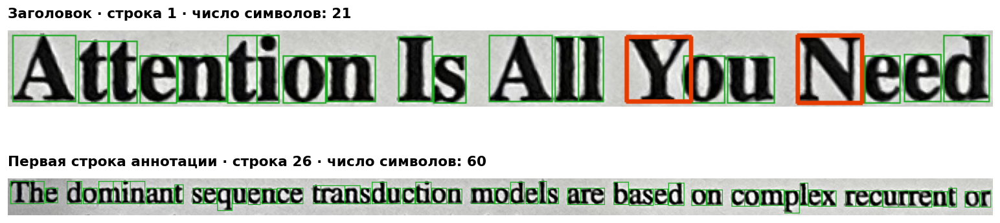

Рамки показывают геометрические гипотезы символов. **Оранжевые рамки** обозначают широкие компоненты, для которых геометрия не дала надёжного разделения. Их число не является полным числом ошибок или доверительным интервалом.

In [19]:
_, symbol_overlay = diagnostic_images(rectified, text_result)
fig, axes = plt.subplots(2, 1, figsize=(13, 4))
title_record = min(line_records, key=lambda record: record["bbox"][1])
for ax, record, label in zip(axes, [title_record, line_records[25]],
                            ["Заголовок", "Первая строка аннотации"]):
    x, y, w, h = record["bbox"]
    margin = 3
    crop = symbol_overlay[max(0, y-margin):y+h+margin, max(0, x-margin):x+w+margin]
    show_image(ax, crop, f"{label} · строка {record['id']} · число символов: {record['character_estimate']}")
plt.tight_layout()
plt.show()
display(Markdown("Рамки показывают геометрические гипотезы символов. **Оранжевые рамки** обозначают "
                 "широкие компоненты, для которых геометрия не дала надёжного разделения. "
                 "Их число не является полным числом ошибок или доверительным интервалом."))

In [20]:
table(["№ строки", "x", "y", "Ширина", "Высота", "Символы"],
      [[record["id"], *record["bbox"], record["character_estimate"]] for record in line_records],
      collapsed=f"Подробный подсчёт по всем {len(line_records)} строкам")

№ строки,x,y,Ширина,Высота,Символы
1,780,632,668,46,21
2,502,947,250,27,14
3,1533,948,259,30,14
4,878,949,230,27,14
5,1230,949,203,27,12
6,525,987,191,34,11
7,1535,988,243,35,12
8,891,989,191,34,10
9,1204,989,242,34,15
10,445,1030,352,33,19


## 8. Ручная проверка и результаты

| Область страницы | Вручную посчитано строк |
|:--|--:|
| Заголовок | 1 |
| Блоки авторов: 4 × 3 + 3 × 3 + 2 | 23 |
| Заголовок Abstract | 1 |
| Аннотация | 13 |
| Заголовок 1 Introduction | 1 |
| Абзац Introduction | 5 |
| Большой абзац сноски | 9 |
| Две короткие сноски | 2 |
| Нижний колонтитул | 1 |
| **Итого** | **56** |

Для символов отдельно показываем шесть строк, использованных при отладке,
и шесть дополнительных контрольных строк, после проверки которых алгоритм
не изменялся. Номера соответствуют нумерованной визуализации; эталонная длина
вычисляется из ручной транскрипции. Это **выборочная проверка**, она не доказывает
точность общего количества символов всей страницы.

In [21]:
MANUAL_LINE_COUNT = 56
# Photo transcriptions are used here only for checking; segmentation does not read them.
control_strings = [
    (1, "Attention Is All You Need"),
    (2, "Ashish Vaswani*"),
    (6, "Google Brain"),
    (10, "avaswani@google.com"),
    (25, "Abstract"),
    (39, "1 Introduction"),
]
holdout_strings = [
    (3, "Jakob Uszkoreit*"),
    (4, "Noam Shazeer*"),
    (5, "Niki Parmar*"),
    (26, "The dominant sequence transduction models are based on complex recurrent or"),
    (38, "best models from the literature."),
    (53, "our research."),
]

def compare_manual(references):
    comparisons = []
    for line_id, text in references:
        record = line_records[line_id - 1]
        expected = len("".join(text.split()))
        actual = record["character_estimate"]
        comparisons.append({"text": text, "id": line_id, "expected": expected,
                            "actual": actual, "error": actual - expected})
    return comparisons

debug_checks = compare_manual(control_strings)
checks = compare_manual(holdout_strings)
display(Markdown("**Строки, использованные при отладке:**"))
table(["Строка", "№", "Вручную", "Алгоритм", "Ошибка"],
      [[c["text"], c["id"], c["expected"], c["actual"], f"{c['error']:+d}"] for c in debug_checks])
display(Markdown("**Дополнительные контрольные строки:**"))
table(["Контрольная строка", "№", "Вручную", "Алгоритм", "Ошибка"],
      [[c["text"], c["id"], c["expected"], c["actual"], f"{c['error']:+d}"] for c in checks])
line_error = summary["line_count"] - MANUAL_LINE_COUNT
sample_mae = float(np.mean([abs(c["error"]) for c in checks]))
sample_absolute_error = sum(abs(c["error"]) for c in checks)
sample_reference_count = sum(c["expected"] for c in checks)
sample_normalized_error = sample_absolute_error / sample_reference_count
display(Markdown(f"**Строки:** алгоритм {summary['line_count']}, вручную {MANUAL_LINE_COUNT}; "
                 f"ошибка {line_error:+d}. **Средняя абсолютная ошибка на {len(checks)} "
                 f"дополнительных строках:** {sample_mae:.2f} символа на строку. "
                 f"Сумма абсолютных ошибок: {sample_absolute_error} из {sample_reference_count} "
                 f"вручную посчитанных символов ({sample_normalized_error:.2%}); "
                 "это результат выбранной выборки, а не оценка ошибки всей страницы."))

**Строки, использованные при отладке:**

Строка,№,Вручную,Алгоритм,Ошибка
Attention Is All You Need,1,21,21,+0
Ashish Vaswani*,2,14,14,+0
Google Brain,6,11,11,+0
avaswani@google.com,10,19,19,+0
Abstract,25,8,8,+0
1 Introduction,39,13,13,+0


**Дополнительные контрольные строки:**

Контрольная строка,№,Вручную,Алгоритм,Ошибка
Jakob Uszkoreit*,3,15,14,-1
Noam Shazeer*,4,12,14,+2
Niki Parmar*,5,11,12,+1
The dominant sequence transduction models are based on complex recurrent or,26,65,60,-5
best models from the literature.,38,28,28,+0
our research.,53,12,13,+1


**Строки:** алгоритм 56, вручную 56; ошибка +0. **Средняя абсолютная ошибка на 6 дополнительных строках:** 1.67 символа на строку. Сумма абсолютных ошибок: 10 из 143 вручную посчитанных символов (6.99%); это результат выбранной выборки, а не оценка ошибки всей страницы.

In [22]:
assert len(corners) == 4 and np.isfinite(homography).all()
assert geometry_ok, "Геометрические допуски не выполнены; нужно уточнение углов."
assert summary["line_count"] == len(line_records)
assert all(record["character_estimate"] == len(record["character_boxes"]) for record in line_records)
assert summary["character_estimate"] == sum(record["character_estimate"] for record in line_records)
display(Markdown(
    f"### Вывод\n\n"
    f"На фотографии **{IMAGE_PATH.name}** автоматически найдены четыре угла листа. "
    f"Исправлена перспектива и уточнён общий наклон на **{correction_angle:.3f}°**. "
    f"Разность направлений двух независимо выделенных печатных линий составляет "
    f"**{parallel_error:.4f}°**, что меньше допуска {PARALLEL_TOLERANCE_DEG:.2f}°.\n\n"
    f"Собственный алгоритм без OCR выделил **{summary['line_count']} строк** "
    f"и получил алгоритмическое число символов без пробелов: **{summary['character_estimate']}**. "
    f"Ручной контроль строк: {MANUAL_LINE_COUNT}; ошибка {line_error:+d}. "
    f"На {len(checks)} контрольных строках средняя абсолютная ошибка — "
    f"{sample_mae:.2f} символа на строку.\n\n"
    "Полного ручного эталона всех символов страницы нет, поэтому абсолютная "
    "точность общего числа символов не установлена. Возможные ошибки связаны "
    "со слипшимися буквами, лигатурами и сложной пунктуацией. "
    "Проверка двух линий подтверждает геометрию заголовка, но не исключает локальный изгиб бумаги."
))

### Вывод

На фотографии **IMG_8304.jpeg** автоматически найдены четыре угла листа. Исправлена перспектива и уточнён общий наклон на **0.289°**. Разность направлений двух независимо выделенных печатных линий составляет **0.0004°**, что меньше допуска 0.20°.

Собственный алгоритм без OCR выделил **56 строк** и получил алгоритмическое число символов без пробелов: **2312**. Ручной контроль строк: 56; ошибка +0. На 6 контрольных строках средняя абсолютная ошибка — 1.67 символа на строку.

Полного ручного эталона всех символов страницы нет, поэтому абсолютная точность общего числа символов не установлена. Возможные ошибки связаны со слипшимися буквами, лигатурами и сложной пунктуацией. Проверка двух линий подтверждает геометрию заголовка, но не исключает локальный изгиб бумаги.